# Bài toán 1: Trực quan hóa dữ liệu giá nhà (Amsterdam House Price)

## 1. Chuẩn bị dữ liệu cho trực quan hóa
+ Nạp tập dữ liệu HousingPricesData.csv từ thư mục data
+ Lọc chọn các cột cần thiết: 'Zip', 'Price', 'Area', 'Room'
+ Tạo thêm biến mới 'PriceperSqm' (Giá trên mỗi m2) bằng cách lấy Price chia cho Area

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
houseprices_data = pd.read_csv("data/HousingPrices-Amsterdam-August-2021.csv")
houseprices_data = houseprices_data[['Zip', 'Price', 'Area', 'Room']]
# 3. Tạo biến PriceperSqm (Giá nhà trên mỗi m2)
houseprices_data['PriceperSqm'] = houseprices_data['Price']/ houseprices_data['Area']

## 2. Trực quan hóa dữ liệu với thư viện Matplotlib
+ Sắp xếp dữ liệu theo giá nhà giảm dần để lấy Top 10 căn nhà/khu vực có giá cao nhất.
+ Thực hiện vẽ biểu đồ cột (Bar chart) từ mức độ cơ bản (Basic) đến nâng cao (Advanced).

In [9]:
# Sắp xếp dữ liệu theo giá nhà (Price) giảm dần
houseprices_sorted = houseprices_data.sort_values('Price', ascending = False)
houseprices_sorted.head()

,Zip,Price,Area,Room,PriceperSqm
195,1017 EL,5950000.0,394,10,15101.522843
837,1075 AH,5850000.0,480,14,12187.500000
305,1016 AE,4900000.0,623,13,7865.168539
103,1017 ZP,4550000.0,497,13,9154.929577
179,1012 JS,4495000.0,178,5,25252.808989


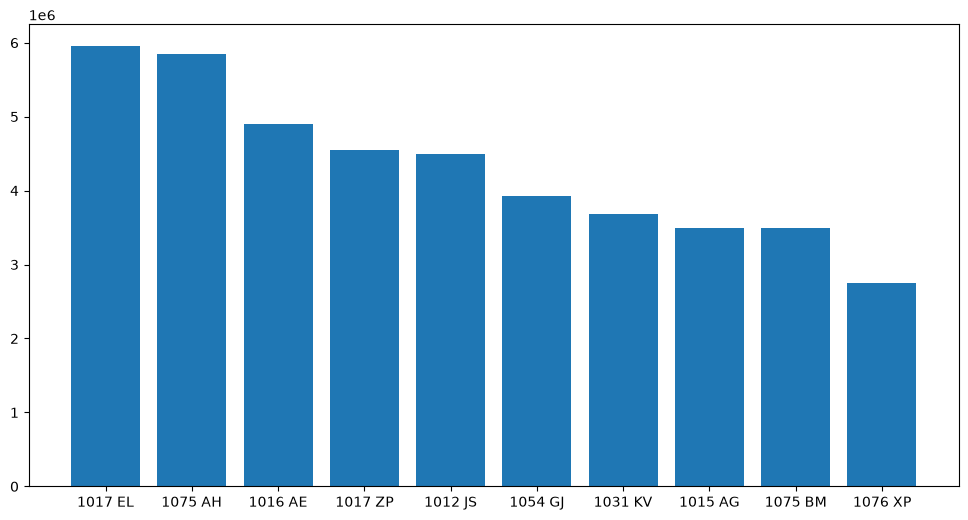

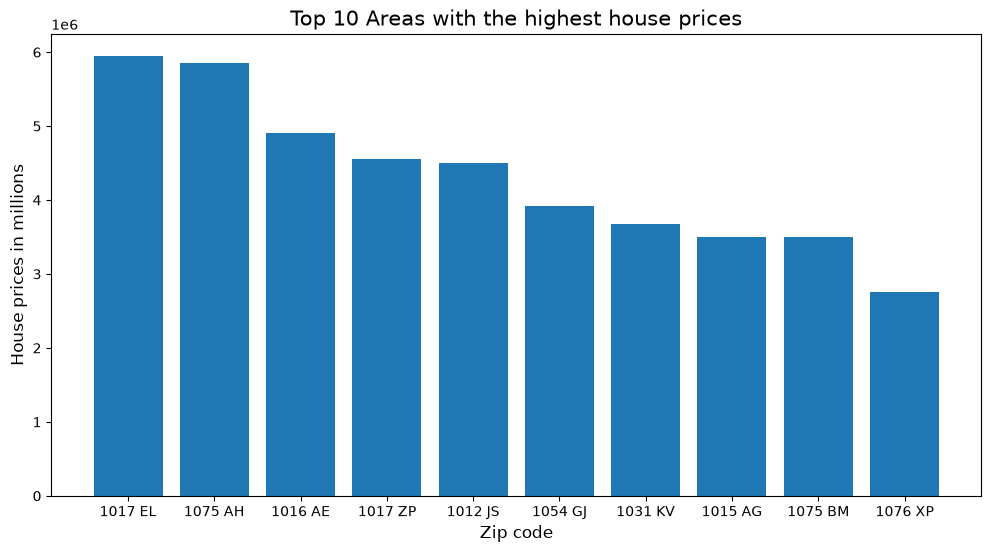

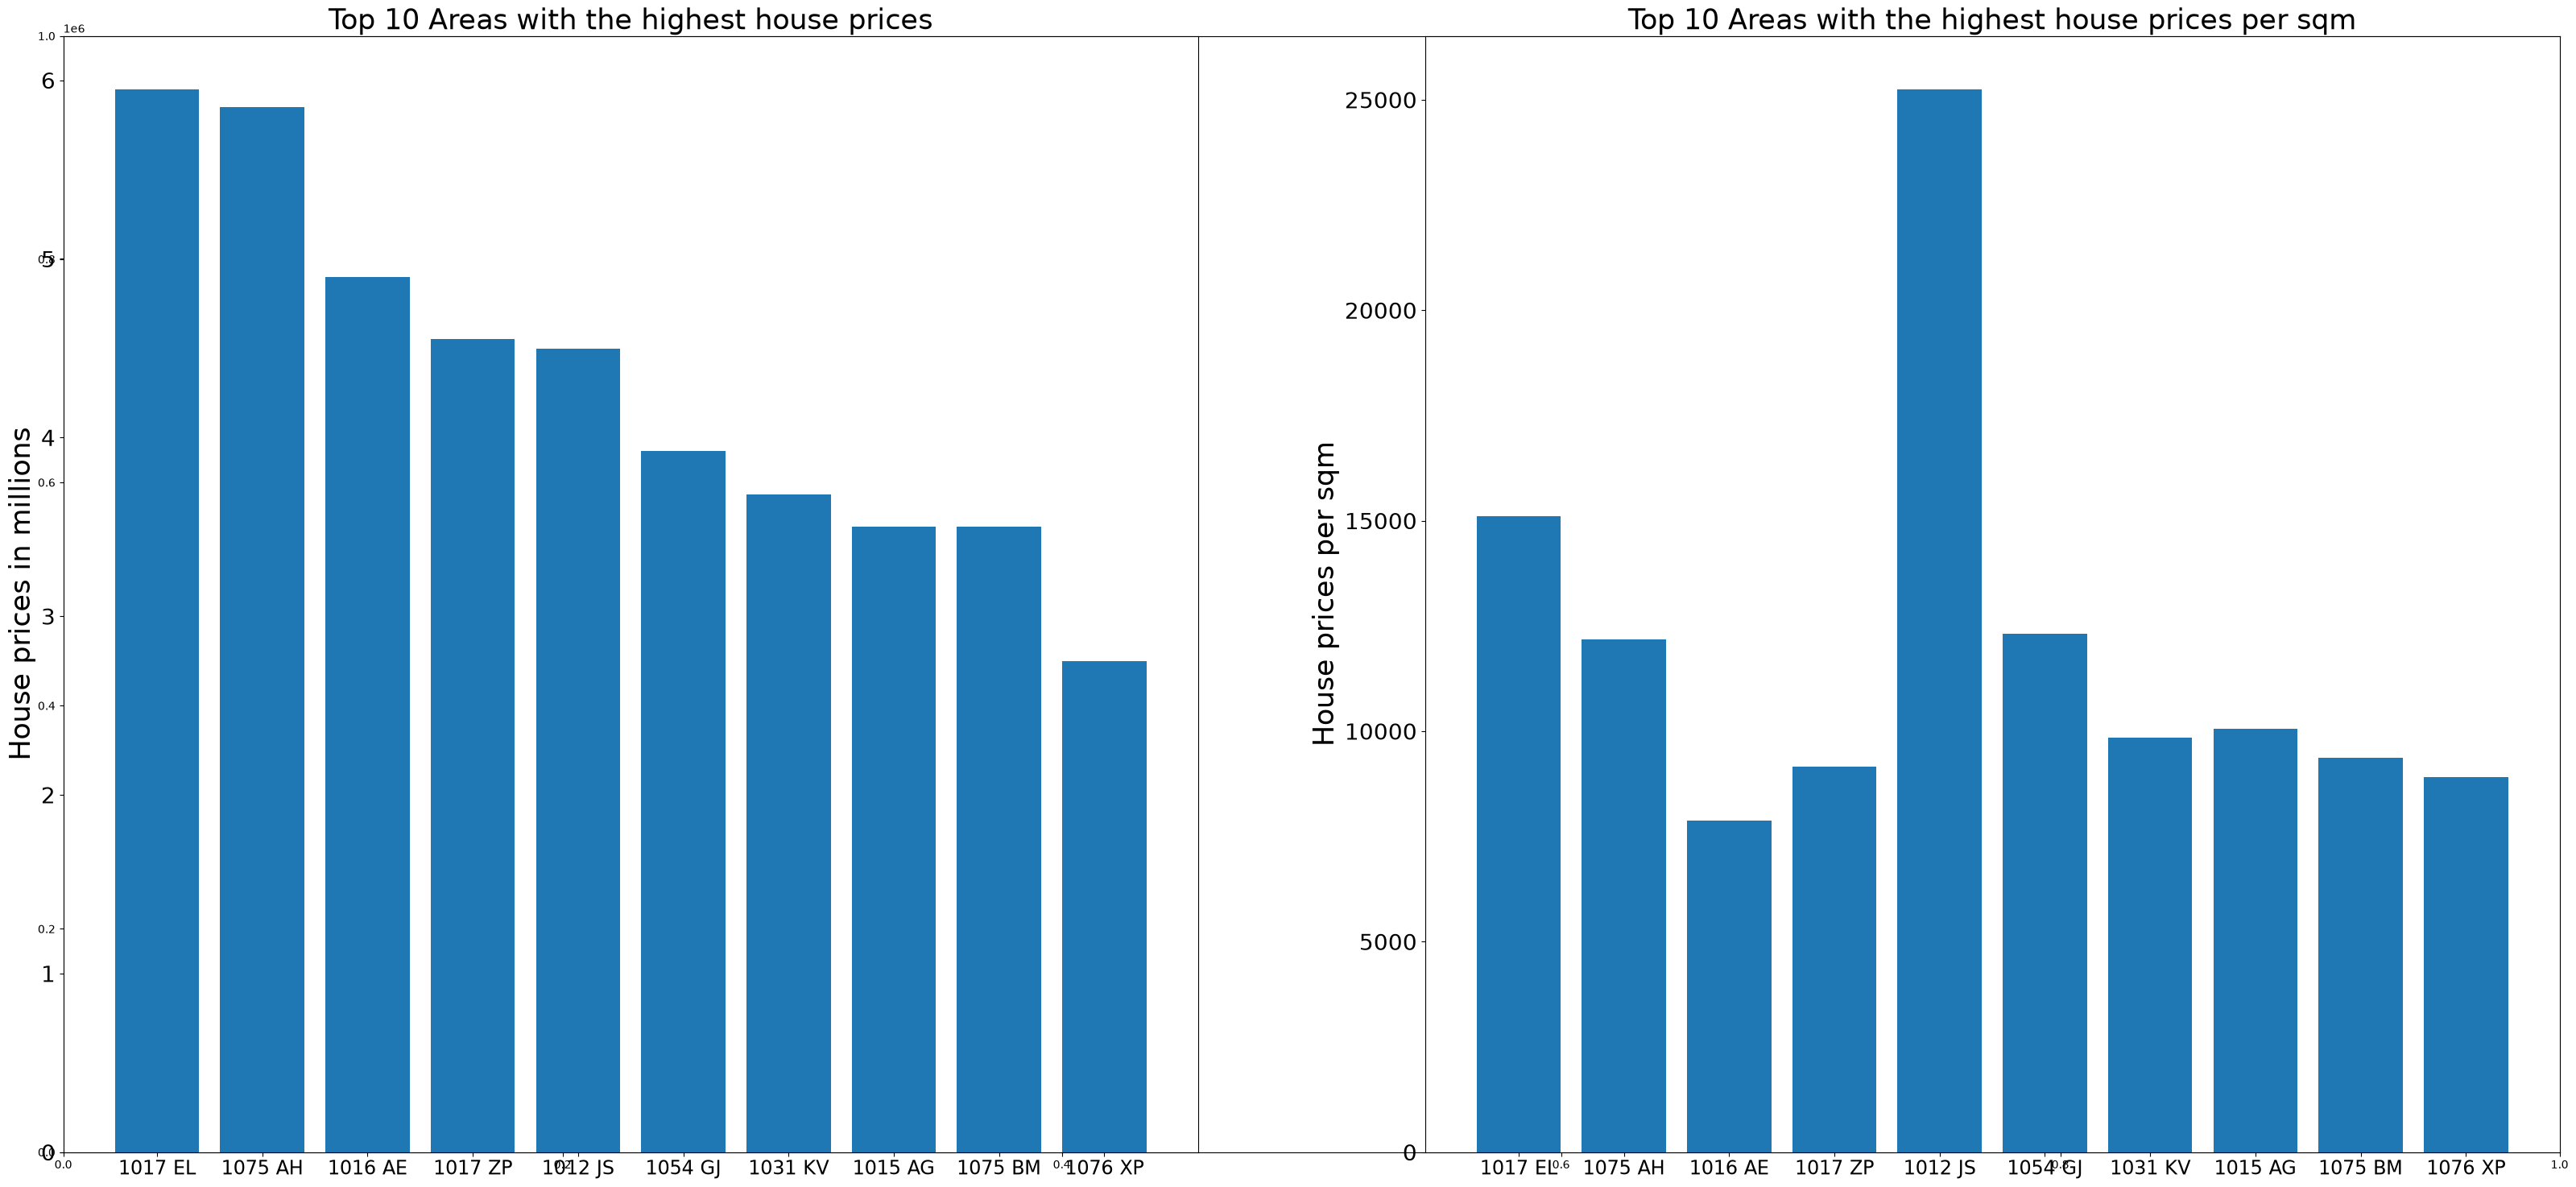

In [10]:
# case 1: basic
plt.figure(figsize= (12,6))
x = houseprices_sorted['Zip'][0:10]
y = houseprices_sorted['Price'][0:10]
plt.bar(x,y)
plt.show()
# case 2: advanced 1
plt.figure(figsize= (12,6))
plt.bar(x,y)
plt.title('Top 10 Areas with the highest house prices', fontsize=15)
plt.xlabel('Zip code', fontsize = 12)
plt.xticks(fontsize=10)
plt.ylabel('House prices in millions', fontsize=12)
plt.yticks(fontsize=10)
plt.show()
# case 3: advanced 2
fig, ax = plt.subplots(figsize=(40,18))
x = houseprices_sorted['Zip'][0:10]
y = houseprices_sorted['Price'][0:10]
y1 = houseprices_sorted['PriceperSqm'][0:10]
plt.subplot(1,2,1)
plt.bar(x,y)
plt.xticks(fontsize=17)
plt.ylabel('House prices in millions', fontsize=25)
plt.yticks(fontsize=20)
plt.title('Top 10 Areas with the highest house prices',
fontsize=25)
plt.subplot(1,2,2)
plt.bar(x,y1)
plt.xticks(fontsize=17)
plt.ylabel('House prices per sqm', fontsize=25)
plt.yticks(fontsize=20)
plt.title('Top 10 Areas with the highest house prices per sqm',
fontsize=25)
plt.show()

## 3. Trực quan hóa dữ liệu với thư viện Seaborn
+ Thư viện Seaborn giúp viết code ngắn gọn hơn và giao diện đẹp mắt hơn so với Matplotlib.
+ Thực hiện lại các bài toán trực quan từ cơ bản đến hiển thị nhiều góc nhìn cùng lúc.

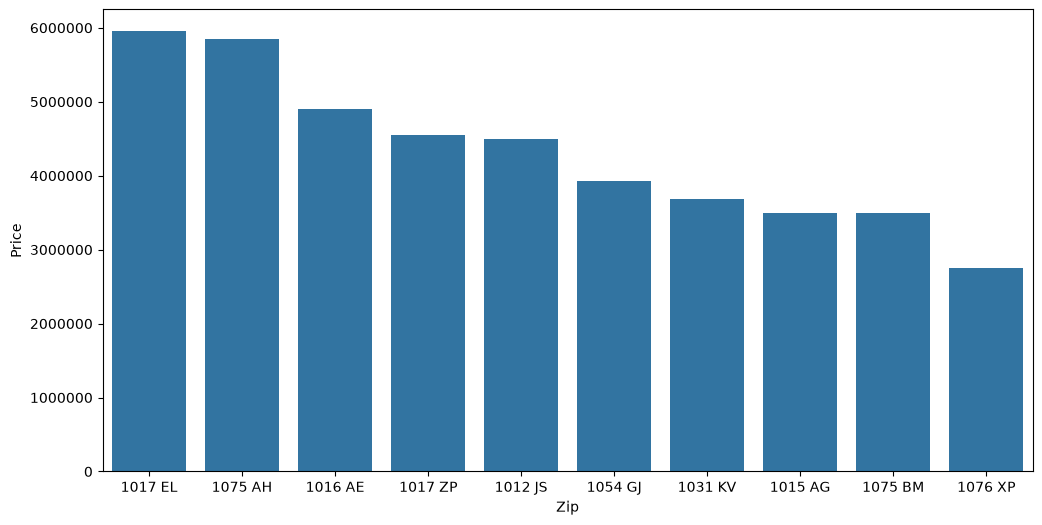

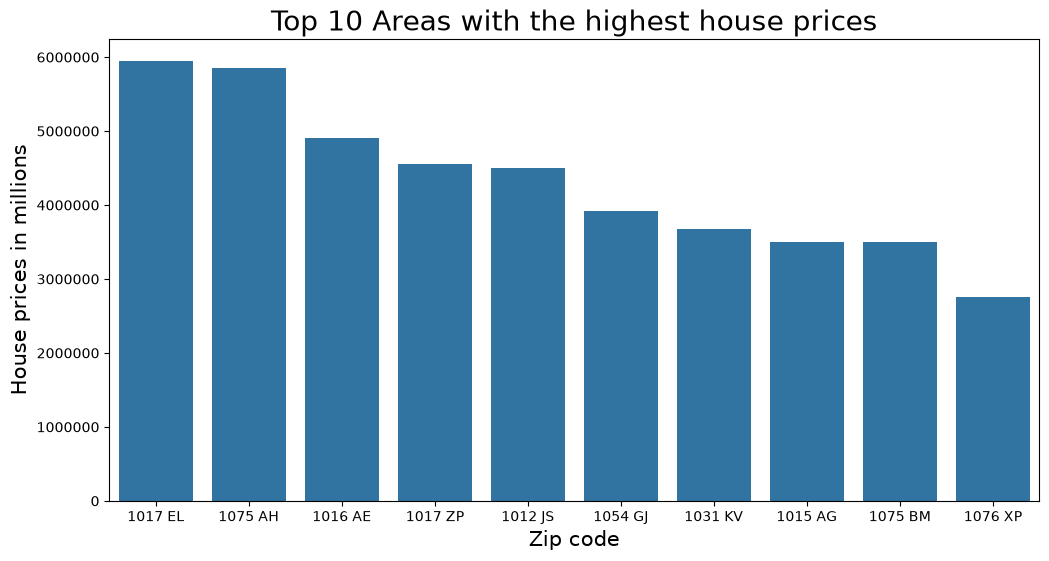

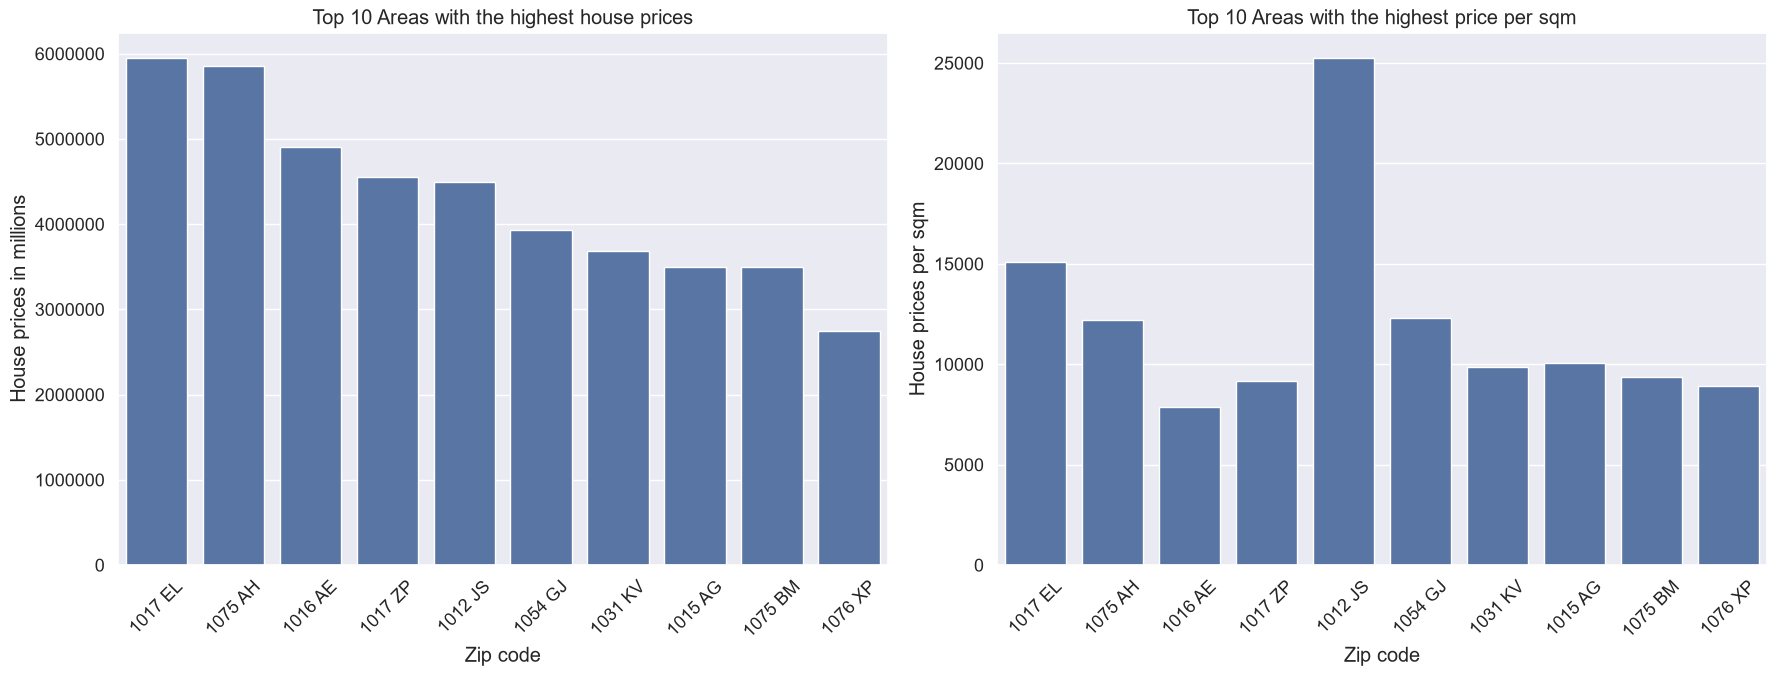

In [11]:
# Reset phông chữ về mặc định trước khi vẽ Seaborn
sns.reset_orig()

data = houseprices_sorted[0:10]

# --- Case 1: Basic ---
plt.figure(figsize=(12, 6))
sns.barplot(data=data, x='Zip', y='Price')
plt.ticklabel_format(style='plain', axis='y')
plt.show()

# --- Case 2: Advanced 1 ---
plt.figure(figsize=(12, 6))
ax = sns.barplot(data=data, x='Zip', y='Price')
plt.ticklabel_format(style='plain', axis='y')
ax.set_xlabel('Zip code', fontsize=15)
ax.set_ylabel('House prices in millions', fontsize=15)
ax.set_title('Top 10 Areas with the highest house prices', fontsize=20)
plt.show()

# --- Case 3: View multiple perspectives at once ---
# Đặt font_scale hợp lý (1.2 thay vì 3) để biểu đồ không bị phồng to chữ
sns.set_theme(font_scale=1.2)

fig, ax = plt.subplots(1, 2, figsize=(18, 7))

# Biểu đồ 1: Tổng giá
ax1 = sns.barplot(data=data, x='Zip', y='Price', ax=ax[0])
ax1.ticklabel_format(style='plain', axis='y')
ax1.set_xlabel('Zip code')
ax1.set_ylabel('House prices in millions')
ax1.set_title('Top 10 Areas with the highest house prices')
ax1.tick_params(axis='x', rotation=45)

# Biểu đồ 2: Đơn giá trên m2
ax2 = sns.barplot(data=data, x='Zip', y='PriceperSqm', ax=ax[1])
ax2.set_xlabel('Zip code')
ax2.set_ylabel('House prices per sqm')
ax2.set_title('Top 10 Areas with the highest price per sqm')
ax2.tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

# Reset lại theme để giữ Kernel luôn sạch
sns.reset_orig()

## 3. phân tích đơn biến dựa vào boxplot

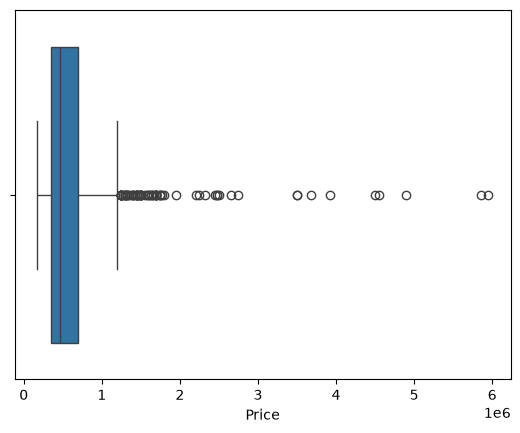

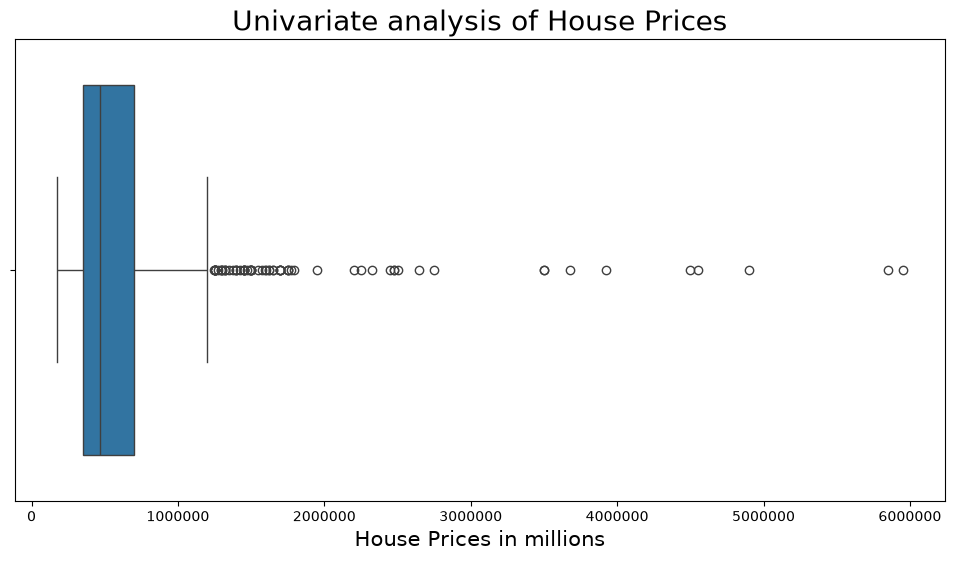

In [12]:
# case 1: Create a boxplot using the boxplot method
sns.boxplot(data = houseprices_data, x= houseprices_data["Price"])
# case 2: advanced
plt.figure(figsize= (12,6))
ax = sns.boxplot(data = houseprices_data, x= houseprices_data["Price"])
ax.set_xlabel('House Prices in millions',fontsize = 15)
ax.set_title('Univariate analysis of House Prices', fontsize= 20)
plt.ticklabel_format(style='plain', axis='x')
plt.show()

## 4. Phân tích dữ liệu đơn biến dựa vào violin plot

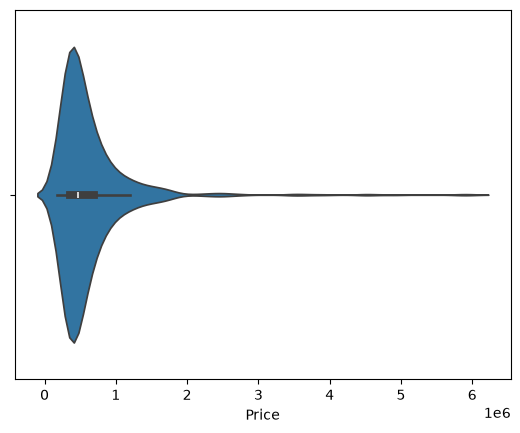

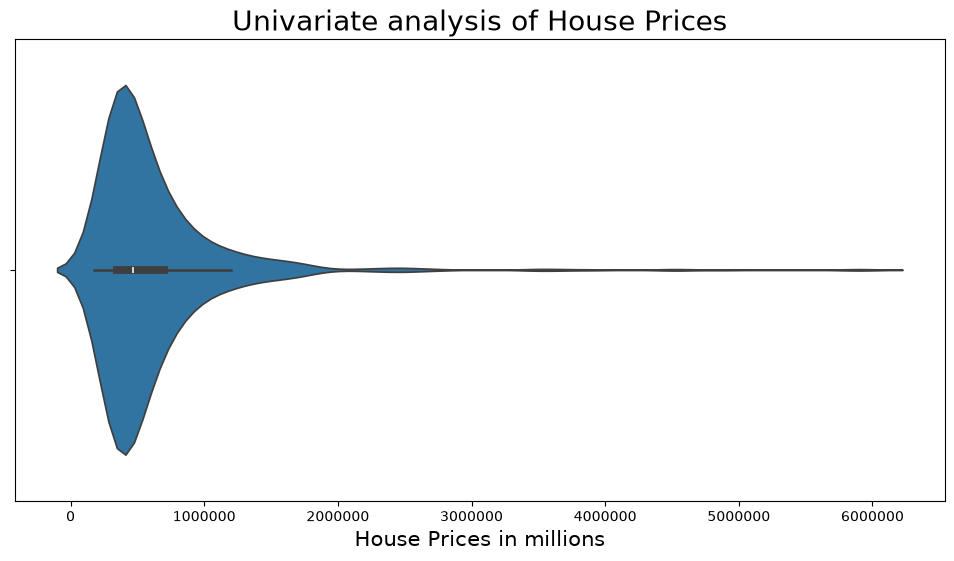

In [13]:
# case 1: basic
sns.violinplot(data = houseprices_data, x= houseprices_data["Price"])
# case 2: advanced
plt.figure(figsize= (12,6))
ax = sns.violinplot(data = houseprices_data, x=houseprices_data["Price"])
ax.set_xlabel('House Prices in millions',fontsize = 15)
ax.set_title('Univariate analysis of House Prices', fontsize= 20)
plt.ticklabel_format(style='plain', axis='x')
plt.show()

In [14]:
houseprices_data.describe()

,Price,Area,Room,PriceperSqm
count,9.200000e+02,924.000000,924.000000,920.000000
mean,6.220654e+05,95.952381,3.571429,6479.852299
std,5.389942e+05,57.447436,1.592332,2219.265218
min,1.750000e+05,21.000000,1.000000,2430.555556
25%,3.500000e+05,60.750000,3.000000,4649.086379
50%,4.670000e+05,83.000000,3.000000,6578.947368
75%,7.000000e+05,113.000000,4.000000,7768.912530
max,5.950000e+06,623.000000,14.000000,25252.808989
